# problem 2 on the f distribution 

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from scipy.stats import f

# Comparing teaching methods

In [42]:
method_A = np.array([70	,72	,68	,70	,75])
method_B = np.array([80,82,78,80,85])
method_C = np.array([90,92,88,90,95])
df = pd.DataFrame({"Method_A":method_A,"Method_B":method_B,"Method_C":method_C})
df

,Method_A,Method_B,Method_C
0,70,80,90
1,72,82,92
2,68,78,88
3,70,80,90
4,75,85,95


In [43]:
mean_of_A = df["Method_A"].mean()
mean_of_B = df["Method_B"].mean()
mean_of_C = df["Method_C"].mean()
grand_mean = df[["Method_A","Method_B","Method_C"]].values.mean()
print("mean of method A : ",mean_of_A)
print("mean of method B : ",mean_of_B)
print("mean of method C : ",mean_of_C)
print("grand mean : ",grand_mean)

mean of method A :  71.0
mean of method B :  81.0
mean of method C :  91.0
grand mean :  81.0


In [44]:
k = 3 
N = len(df)* k
dof_between = k -1 
dof_within  = N - k
dof_total = dof_between + dof_within
print("Degree of freedom between : ",dof_between)
print("Degree of freedom within : ",dof_within)
print("Degree of freedom total : ",dof_total)


Degree of freedom between :  2
Degree of freedom within :  12
Degree of freedom total :  14


# sum of  square between and sum of square within 

In [45]:
ss_between  = len(df["Method_A"]) * (mean_of_A - grand_mean) ** 2 + len(df["Method_B"])* (mean_of_B - grand_mean) ** 2  + len(df["Method_C"]) * (mean_of_C - grand_mean) ** 2
print("sum of square between : ",ss_between)

sum of square between :  1000.0


In [46]:
ss_within = ((df["Method_A"] - mean_of_A) ** 2 ) .sum() + ((df["Method_B"] - mean_of_B)** 2 ).sum() + ((df["Method_C"] - mean_of_C )** 2 ).sum()
print("sum of square within : ",ss_within)




sum of square within :  84.0


In [47]:
mean_ss_between = ss_between / dof_between
mean_ss_within = ss_within / dof_within
print("mean square between : ",mean_ss_between)
print("mean square within : ",mean_ss_within)

mean square between :  500.0
mean square within :  7.0


In [48]:
F_test_Stat = mean_ss_between / mean_ss_within
print("F test stats : ",F_test_Stat)

F test stats :  71.42857142857143


In [49]:
alpha = 0.05
p_value = f.sf(F_test_Stat,dof_between,dof_within)
critical_value = f.ppf(1- alpha ,dof_between,dof_within)
print("critical value : ",critical_value)
print("p value : ",p_value)

critical value :  3.8852938346523924
p value :  2.1652099947594104e-07


In [50]:
if p_value < alpha :
    print("Decision : we reject the null hypothesis .")
    print("Conclusion : there are sufficient evidence at 5 % significane level that the three teaching method have different average marks . ")
else : 
    print("Decision : we are fail to reject the null hypothesis .")
    print("conclusion : there are not sufficeient evidence at 5 % significance level so the three teaching method produce same average marks .")

Decision : we reject the null hypothesis .
Conclusion : there are sufficient evidence at 5 % significane level that the three teaching method have different average marks . 


# visualize the data 

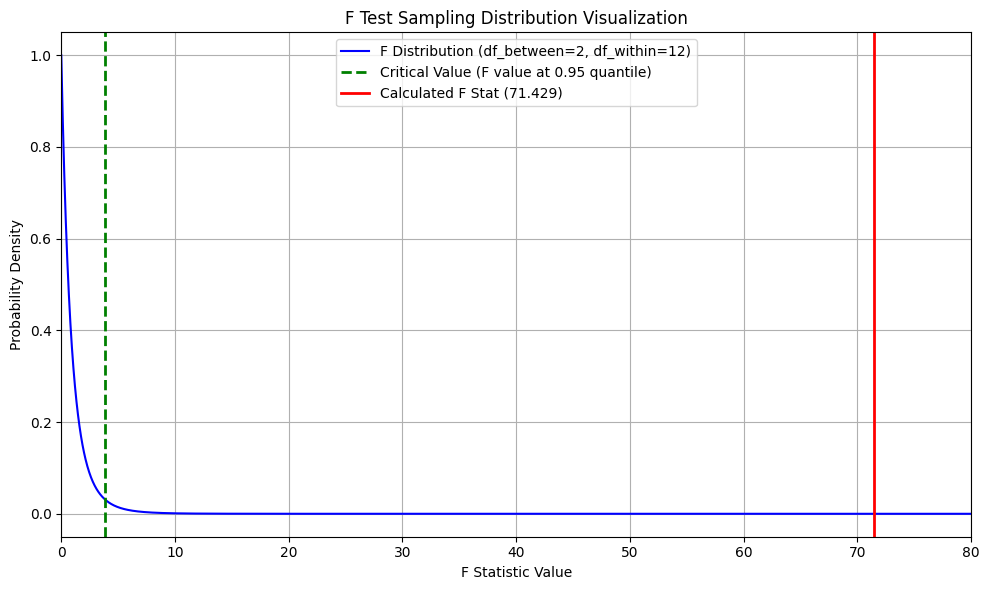

In [58]:


x = np.linspace(0, 80, 3000)
y = f.pdf(x, dof_between, dof_within)
plt.figure(figsize=(10, 6))

# 1. Plot the theoretical F-distribution curve
plt.plot(x, y, label=f'F Distribution (df_between={dof_between}, df_within={dof_within})', color='blue')
# 2. Mark the Critical Value (The boundary for alpha)
plt.axvline(critical_value, linestyle="--", color="green", linewidth=2, label=f'Critical Value (F value at {1-alpha:.2f} quantile)')
# 3. Mark Your Calculated F-Statistic
plt.axvline(F_test_Stat, color="red", linestyle="solid", linewidth=2, label=f'Calculated F Stat ({F_test_Stat:.3f})')
plt.xlim(0,80)
plt.title("F Test Sampling Distribution Visualization")
plt.xlabel("F Statistic Value")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

